<a href="https://colab.research.google.com/github/amashaE/PUSL3205-LLM-Practical-Portfolio/blob/main/Lab-03-Developing%20a%20Tiny%20Transformer%20Language%20Model/Lab_Sheet_3_Tiny_Transformer%20(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Sheet 3 – Developing a Tiny Transformer Language Model




## 1. Load the dataset


### 1.1 Install and import the required libraries

In [ ]:
!pip -q install datasets

In [ ]:
import math
import random
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from datasets import load_dataset
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


### 1.2 Load and explore the dataset

Load the first 5,000 stories from the training split. Display a few examples and examine the character and word lengths.

In [ ]:
N_STORIES = 5000

dataset = load_dataset(
    "roneneldan/TinyStories",
    split=f"train[:{N_STORIES}]"
)

print(dataset)
print("Number of loaded stories:", len(dataset))

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

data/train-00002-of-00004-a26307300439e9(…): reconstructing file:   0%|          |  0.00B /  246MB            

... (4 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Dataset({
    features: ['text'],
    num_rows: 5000
})
Number of loaded stories: 5000


In [ ]:
# Display three example stories
for i in range(3):
    print(f"--- Story {i + 1} ---")
    print(dataset[i]["text"][:800])
    print()

--- Story 1 ---
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.

--- Story 2 ---
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park when he saw a big tree. The tree had

In [ ]:
# Examine story lengths
texts = [story.strip() for story in dataset["text"] if story.strip()]

character_lengths = [len(story) for story in texts]
word_lengths = [len(story.split()) for story in texts]

print(f"Number of usable stories: {len(texts)}")
print(f"Average characters per story: {sum(character_lengths) / len(character_lengths):.2f}")
print(f"Minimum characters: {min(character_lengths)}")
print(f"Maximum characters: {max(character_lengths)}")
print(f"Average words per story: {sum(word_lengths) / len(word_lengths):.2f}")

Number of usable stories: 5000
Average characters per story: 835.35
Minimum characters: 253
Maximum characters: 4123
Average words per story: 162.16


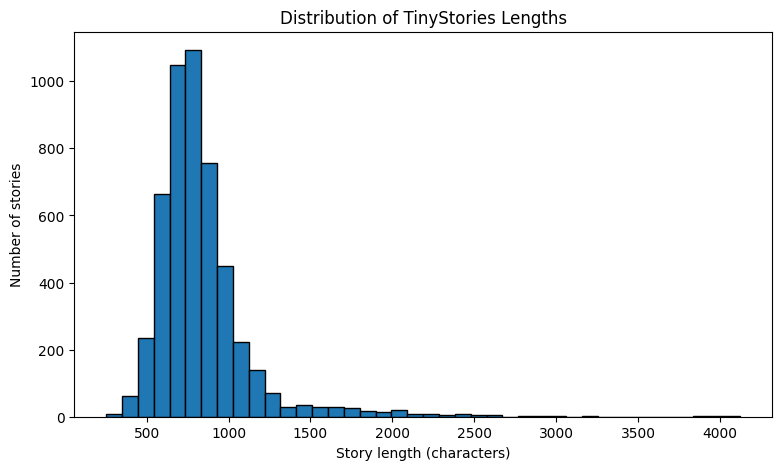

In [ ]:
plt.figure(figsize=(9, 5))
plt.hist(character_lengths, bins=40, edgecolor="black")
plt.xlabel("Story length (characters)")
plt.ylabel("Number of stories")
plt.title("Distribution of TinyStories Lengths")
plt.show()

### Observation

-The stories are not all the same length.

-The histogram helps show how story lengths are distributed in the selected subset.

## 2. Preprocess the text and tokenize at character level


In [ ]:
# Combine stories while preserving a separator between them
text = "\n\n".join(texts)

# Build the character vocabulary
chars = sorted(set(text))
vocab_size = len(chars)

stoi = {character: index for index, character in enumerate(chars)}
itos = {index: character for character, index in stoi.items()}

def encode(string):
    # All characters in the input must exist in the vocabulary
    return [stoi[character] for character in string]

def decode(token_ids):
    return "".join(itos[int(token_id)] for token_id in token_ids)

# Convert the complete text into integer token IDs
all_tokens = torch.tensor(encode(text), dtype=torch.long)

print("Vocabulary size:", vocab_size)
print("Total characters:", len(text))
print("Encoded token count:", len(all_tokens))
print("Example text:", repr("Once upon a time"))
print("Encoded example:", encode("Once upon a time"))
print("Decoded example:", decode(encode("Once upon a time")))

Vocabulary size: 90
Total characters: 4186738
Encoded token count: 4186738
Example text: 'Once upon a time'
Encoded example: [36, 61, 50, 52, 1, 68, 63, 62, 61, 1, 48, 1, 67, 56, 60, 52]
Decoded example: Once upon a time


### Observation

Character-level tokenization creates a vocabulary from individual characters rather than complete words. It is straightforward to implement and can represent any text made from characters in the vocabulary. However, it generally requires the model to generate more prediction steps than a word-level or subword tokenizer.

## 3. Prepare training and validation data


In [ ]:
BLOCK_SIZE = 128
BATCH_SIZE = 64
TRAIN_RATIO = 0.90

# Split the token stream into training and validation portions
split_index = int(TRAIN_RATIO * len(all_tokens))

train_tokens = all_tokens[:split_index]
val_tokens = all_tokens[split_index:]

def create_sequences(token_data, block_size):
    # Each input position is paired with the character immediately after it
    usable_length = ((len(token_data) - 1) // block_size) * block_size

    inputs = token_data[:usable_length].view(-1, block_size)
    targets = token_data[1:usable_length + 1].view(-1, block_size)

    return TensorDataset(inputs, targets)

train_dataset = create_sequences(train_tokens, BLOCK_SIZE)
val_dataset = create_sequences(val_tokens, BLOCK_SIZE)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training sequences:", len(train_dataset))
print("Validation sequences:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# Display one input-target example
example_x, example_y = train_dataset[0]

print("\nInput sequence:")
print(repr(decode(example_x[:60])))

print("\nTarget sequence:")
print(repr(decode(example_y[:60])))

Training sequences: 29437
Validation sequences: 3270
Training batches: 459
Validation batches: 52

Input sequence:
'One day, a little girl named Lily found a needle in her room'

Target sequence:
'ne day, a little girl named Lily found a needle in her room.'


### Observation

The input and target sequences are aligned so that each target character is the next character after the corresponding input character. The training set is used to update model parameters, while the validation set is used to monitor performance on data not used for training.

## 4. Build the Transformer architecture

The Transformer contains the components:

- **Token embeddings**
- **Positional embeddings**
- **Masked multi-head self-attention:**
- **Feed-forward network:**
- **Residual connections:**
- **Layer normalization:**

In [ ]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()

        assert n_embd % n_head == 0, "Embedding size must be divisible by number of heads."

        self.n_head = n_head
        self.head_dim = n_embd // n_head

        # One linear layer produces query, key and value vectors
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.projection = nn.Linear(n_embd, n_embd)

        self.attention_dropout = nn.Dropout(dropout)
        self.residual_dropout = nn.Dropout(dropout)

        # Causal mask: a position can only attend to itself and earlier positions
        mask = torch.tril(torch.ones(block_size, block_size))
        self.register_buffer(
            "mask",
            mask.view(1, 1, block_size, block_size)
        )

    def forward(self, x):
        batch_size, sequence_length, embedding_size = x.shape

        q, k, v = self.qkv(x).split(embedding_size, dim=2)

        # Split embedding dimensions into attention heads
        q = q.view(batch_size, sequence_length, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(batch_size, sequence_length, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(batch_size, sequence_length, self.n_head, self.head_dim).transpose(1, 2)

        # Scaled dot-product attention
        attention_scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)

        # Prevent attention to future positions
        attention_scores = attention_scores.masked_fill(
            self.mask[:, :, :sequence_length, :sequence_length] == 0,
            float("-inf")
        )

        attention_weights = F.softmax(attention_scores, dim=-1)
        attention_weights = self.attention_dropout(attention_weights)

        output = attention_weights @ v

        # Combine the attention heads
        output = output.transpose(1, 2).contiguous().view(
            batch_size, sequence_length, embedding_size
        )

        output = self.projection(output)
        return self.residual_dropout(output)


class TransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()

        self.layer_norm_1 = nn.LayerNorm(n_embd)
        self.attention = CausalSelfAttention(
            n_embd, n_head, block_size, dropout
        )

        self.layer_norm_2 = nn.LayerNorm(n_embd)

        self.feed_forward = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        # Residual connection around attention
        x = x + self.attention(self.layer_norm_1(x))

        # Residual connection around feed-forward network
        x = x + self.feed_forward(self.layer_norm_2(x))

        return x


class TinyTransformer(nn.Module):
    def __init__(
        self,
        vocab_size,
        block_size,
        n_embd=128,
        n_head=4,
        n_layer=4,
        dropout=0.1
    ):
        super().__init__()

        self.block_size = block_size

        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.embedding_dropout = nn.Dropout(dropout)

        self.transformer_blocks = nn.Sequential(
            *[
                TransformerBlock(n_embd, n_head, block_size, dropout)
                for _ in range(n_layer)
            ]
        )

        self.final_layer_norm = nn.LayerNorm(n_embd)
        self.output_head = nn.Linear(n_embd, vocab_size, bias=False)

        # Share weights between token embeddings and output projection
        self.output_head.weight = self.token_embedding.weight

        self.apply(self.initialize_weights)

    def initialize_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)

        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, targets=None):
        batch_size, sequence_length = input_ids.shape

        positions = torch.arange(
            sequence_length,
            device=input_ids.device
        )

        token_vectors = self.token_embedding(input_ids)
        position_vectors = self.position_embedding(positions)

        x = self.embedding_dropout(token_vectors + position_vectors)
        x = self.transformer_blocks(x)
        x = self.final_layer_norm(x)

        logits = self.output_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss

    @torch.no_grad()
    def generate(
        self,
        input_ids,
        max_new_tokens=300,
        temperature=0.8,
        top_k=20
    ):
        self.eval()

        for _ in range(max_new_tokens):
            # Keep only the most recent context that fits the model
            context = input_ids[:, -self.block_size:]

            logits, _ = self(context)

            # Use the final position to predict the next character
            logits = logits[:, -1, :] / max(temperature, 1e-5)

            # Restrict sampling to the top-k most likely characters
            if top_k is not None and top_k > 0:
                top_values, _ = torch.topk(
                    logits,
                    min(top_k, logits.size(-1))
                )
                logits[logits < top_values[:, [-1]]] = -float("inf")

            probabilities = F.softmax(logits, dim=-1)

            next_character = torch.multinomial(
                probabilities,
                num_samples=1
            )

            input_ids = torch.cat(
                (input_ids, next_character),
                dim=1
            )

        return input_ids

### Explanation of the architecture

The causal mask is important for language modelling because the model must predict the next character without seeing future characters. Multi-head attention uses multiple attention heads to learn different relationships in the input. The feed-forward network further transforms the representations. Residual connections and layer normalization support stable information flow through the Transformer.

## 5. Initialize the model


In [ ]:
BASE_CONFIG = {
    "vocab_size": vocab_size,
    "block_size": BLOCK_SIZE,
    "n_embd": 128,
    "n_head": 4,
    "n_layer": 4,
    "dropout": 0.1
}

model = TinyTransformer(**BASE_CONFIG).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=0.01
)

number_of_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print(f"Number of model parameters: {number_of_parameters:,}")

# Check that the model produces logits and a loss
sample_inputs, sample_targets = next(iter(train_loader))
sample_inputs = sample_inputs.to(device)
sample_targets = sample_targets.to(device)

with torch.no_grad():
    sample_logits, initial_loss = model(sample_inputs, sample_targets)

print("Logits shape:", sample_logits.shape)
print("Initial cross-entropy loss:", round(initial_loss.item(), 4))
print("Random baseline reference ln(vocabulary size):", round(math.log(vocab_size), 4))

Number of model parameters: 821,248
Logits shape: torch.Size([64, 128, 90])
Initial cross-entropy loss: 4.4966
Random baseline reference ln(vocabulary size): 4.4998


## 6. Train the model


In [ ]:
def evaluate_model(model, data_loader):
    model.eval()

    total_loss = 0.0
    total_items = 0

    with torch.no_grad():
        for inputs, targets in data_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            _, loss = model(inputs, targets)

            batch_size = inputs.size(0)
            total_loss += loss.item() * batch_size
            total_items += batch_size

    return total_loss / total_items


def train_model(
    n_layer=4,
    n_head=4,
    n_embd=128,
    epochs=5,
    learning_rate=1e-3,
    dropout=0.1
):
    # Reset the seed so experiments are more reproducible
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    config = {
        "vocab_size": vocab_size,
        "block_size": BLOCK_SIZE,
        "n_embd": n_embd,
        "n_head": n_head,
        "n_layer": n_layer,
        "dropout": dropout
    }

    model = TinyTransformer(**config).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=0.01
    )

    total_steps = max(1, epochs * len(train_loader))

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=total_steps
    )

    history = {
        "train_loss": [],
        "validation_loss": [],
        "validation_perplexity": []
    }

    parameter_count = sum(p.numel() for p in model.parameters())

    print("Configuration:", config)
    print(f"Parameters: {parameter_count:,}")
    print("Training device:", device)

    for epoch in range(1, epochs + 1):
        model.train()

        running_loss = 0.0
        start_time = time.time()

        for inputs, targets in train_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            # Forward pass
            _, loss = model(inputs, targets)

            # Clear old gradients
            optimizer.zero_grad(set_to_none=True)

            # Backpropagation
            loss.backward()

            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            # Update parameters and learning rate
            optimizer.step()
            scheduler.step()

            running_loss += loss.item()

        average_train_loss = running_loss / len(train_loader)
        validation_loss = evaluate_model(model, val_loader)
        validation_perplexity = math.exp(validation_loss)

        history["train_loss"].append(average_train_loss)
        history["validation_loss"].append(validation_loss)
        history["validation_perplexity"].append(validation_perplexity)

        elapsed = time.time() - start_time

        print(
            f"Epoch {epoch}/{epochs} | "
            f"Training loss: {average_train_loss:.4f} | "
            f"Validation loss: {validation_loss:.4f} | "
            f"Perplexity: {validation_perplexity:.2f} | "
            f"Time: {elapsed:.1f}s"
        )

    return model, config, history


## 7. Monitor training


In [ ]:
def plot_training_history(history, title="Training and Validation Loss"):
    epochs_range = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(9, 5))
    plt.plot(
        epochs_range,
        history["train_loss"],
        marker="o",
        label="Training loss"
    )
    plt.plot(
        epochs_range,
        history["validation_loss"],
        marker="o",
        label="Validation loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Cross-entropy loss")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

### 7.1 Train the baseline model

The baseline configuration uses four Transformer layers, four attention heads, an embedding size of 128 and five training epochs.

Configuration: {'vocab_size': 90, 'block_size': 128, 'n_embd': 128, 'n_head': 4, 'n_layer': 4, 'dropout': 0.1}
Parameters: 821,248
Training device: cuda
Epoch 1/5 | Training loss: 2.1849 | Validation loss: 1.6626 | Perplexity: 5.27 | Time: 14.2s
Epoch 2/5 | Training loss: 1.5662 | Validation loss: 1.3176 | Perplexity: 3.73 | Time: 14.7s
Epoch 3/5 | Training loss: 1.3402 | Validation loss: 1.1910 | Perplexity: 3.29 | Time: 14.0s
Epoch 4/5 | Training loss: 1.2468 | Validation loss: 1.1397 | Perplexity: 3.13 | Time: 14.0s
Epoch 5/5 | Training loss: 1.2117 | Validation loss: 1.1284 | Perplexity: 3.09 | Time: 14.2s


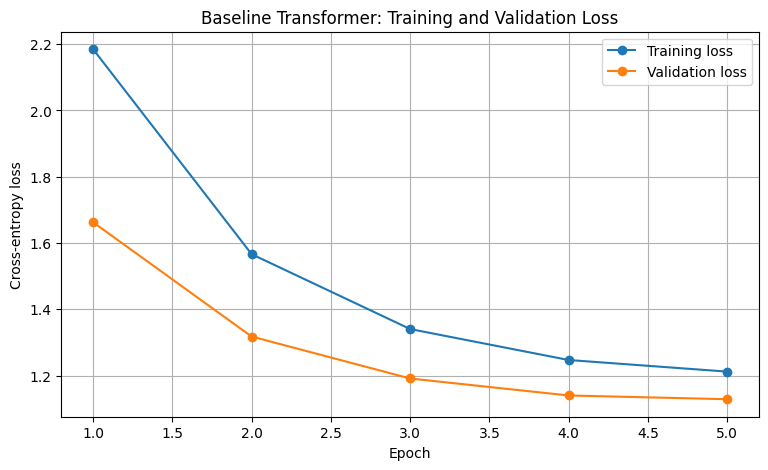

Configuration: {'vocab_size': 90, 'block_size': 128, 'n_embd': 128, 'n_head': 4, 'n_layer': 4, 'dropout': 0.1}
Parameters: 821,248
Training device: cuda
Epoch 1/5 | Training loss: 2.1849 | Validation loss: 1.6626 | Perplexity: 5.27 | Time: 14.4s
Epoch 2/5 | Training loss: 1.5662 | Validation loss: 1.3176 | Perplexity: 3.73 | Time: 14.5s
Epoch 3/5 | Training loss: 1.3403 | Validation loss: 1.1910 | Perplexity: 3.29 | Time: 14.6s
Epoch 4/5 | Training loss: 1.2468 | Validation loss: 1.1397 | Perplexity: 3.13 | Time: 14.8s
Epoch 5/5 | Training loss: 1.2117 | Validation loss: 1.1284 | Perplexity: 3.09 | Time: 14.9s

Training completed!


In [ ]:
plot_training_history(
    baseline_history,
    title="Baseline Transformer: Training and Validation Loss"
)

# Train the baseline Transformer model

EPOCHS = 5

baseline_model, baseline_config, baseline_history = train_model(
    n_layer=4,
    n_head=4,
    n_embd=128,
    epochs=EPOCHS,
    learning_rate=1e-3,
    dropout=0.1
)

print("\nTraining completed!")


### Observation
The Transformer model was successfully trained for five epochs using the CUDA-enabled GPU. During training, the model predicted the next character in each sequence, calculated cross-entropy loss, and updated its parameters through backpropagation. The training loss decreased from 2.1849 in Epoch 1 to 1.2117 in Epoch 5, indicating that the model progressively learned patterns in the training data.
Both training and validation losses decreased consistently throughout the five epochs. Training loss decreased from 2.1849 to 1.2117, while validation loss decreased from 1.6626 to 1.1284. This indicates that the model improved its predictions on both training and unseen validation data.

The validation perplexity also decreased from 5.27 to 3.09, showing that the model became better at predicting the next character. Since the validation loss also decreased rather than increasing, there is no clear indication of overfitting during these five epochs.

Overall, the loss values suggest that the Transformer model learned effectively during the training process.

## 8. Evaluate the model using validation loss and perplexity

In [ ]:
final_validation_loss = evaluate_model(baseline_model, val_loader)
final_perplexity = math.exp(final_validation_loss)

print(f"Final validation loss: {final_validation_loss:.4f}")
print(f"Final validation perplexity: {final_perplexity:.2f}")

Final validation loss: 1.1284
Final validation perplexity: 3.09


### Observation
The final validation loss of 1.1284 indicates that the model performs well in predicting the next character on unseen validation data. The perplexity of 3.09 means that the model has an average uncertainty equivalent to approximately 3 possible next-character choices. Overall, these results suggest that the model has learned useful patterns from the TinyStories dataset.

## 9. Generate stories


In [ ]:
def generate_story(
    model,
    prompt="Once upon a time",
    max_new_tokens=300,
    temperature=0.8,
    top_k=20
):
    model.eval()

    # Remove prompt characters that are not present in the vocabulary
    prompt = "".join(
        character for character in prompt
        if character in stoi
    )

    if not prompt:
        prompt = "\n"

    input_ids = torch.tensor(
        [encode(prompt)],
        dtype=torch.long,
        device=device
    )

    generated_ids = model.generate(
        input_ids,
        max_new_tokens=max_new_tokens,
        temperature=temperature,
        top_k=top_k
    )

    return decode(generated_ids[0].tolist())


print(generate_story(
    baseline_model,
    prompt="Once upon a time",
    max_new_tokens=300,
    temperature=0.8,
    top_k=20
))

Once upon a time, there was a proud of the could fillower that he grabbed he loved to get up together and make her mom to read his it. He said to help and said, "Don't know the feel fish. I wonder my you. I made picture it!"

Jack and Sarah was very sad. "It's explore and have to the tree," she ran and asked he sai


In [ ]:
# Try different starting prompts
prompts = [
    "One day, a little girl",
    "The little dog",
    "Once upon a time"
]

for prompt in prompts:
    print("=" * 70)
    print("Prompt:", prompt)
    print(generate_story(
        baseline_model,
        prompt=prompt,
        max_new_tokens=180,
        temperature=0.8,
        top_k=20
    ))
    print()

Prompt: One day, a little girl
One day, a little girl named Lily and Jen who have she could have the squirrel who learned the bar and the saw the teachin the paple in the forest. She said, "It's too a good of you can." Max says, "Who

Prompt: The little dog
The little dog named Tim. Tom and Dad how mom and promised the caster of the butterfly. But when the mirch still was a played of picked to their pocket and liked to eat an each a beak tried for 

Prompt: Once upon a time
Once upon a time, there was a little girl named From and Lily. He was sad excited to little boy named Tom was so excited and said, "You can friends."

The little girl was surprise, but the boat an



### Observation
The trained Transformer successfully generated text using all three starting prompts. The generated stories include simple characters, names, and story-like elements, showing that the model learned some basic language patterns from the TinyStories dataset. However, the sentences contain grammatical errors, repetition, and some meaningless word combinations. This indicates that the model has learned basic text patterns but still has limitations in generating coherent and meaningful stories.

## 10. Experiment with model settings

Configuration: {'vocab_size': 90, 'block_size': 128, 'n_embd': 128, 'n_head': 2, 'n_layer': 2, 'dropout': 0.1}
Parameters: 424,704
Training device: cuda
Epoch 1/5 | Training loss: 2.1873 | Validation loss: 1.6686 | Perplexity: 5.30 | Time: 6.7s
Epoch 2/5 | Training loss: 1.5953 | Validation loss: 1.3460 | Perplexity: 3.84 | Time: 6.7s
Epoch 3/5 | Training loss: 1.4174 | Validation loss: 1.2463 | Perplexity: 3.48 | Time: 6.7s
Epoch 4/5 | Training loss: 1.3510 | Validation loss: 1.2071 | Perplexity: 3.34 | Time: 6.6s
Epoch 5/5 | Training loss: 1.3265 | Validation loss: 1.1994 | Perplexity: 3.32 | Time: 6.7s


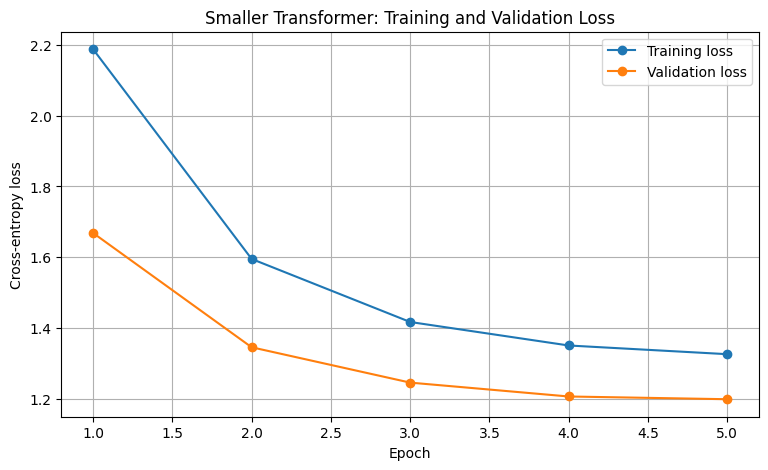

In [ ]:
small_model, small_config, small_history = train_model(
    n_layer=2,
    n_head=2,
    n_embd=128,
    epochs=EPOCHS,
    learning_rate=1e-3,
    dropout=0.1
)

plot_training_history(
    small_history,
    title="Smaller Transformer: Training and Validation Loss"
)

In [ ]:
# Compare the two configurations
comparison = {
    "Baseline (4 layers, 4 heads)": {
        "parameters": sum(p.numel() for p in baseline_model.parameters()),
        "validation_loss": evaluate_model(baseline_model, val_loader)
    },
    "Smaller (2 layers, 2 heads)": {
        "parameters": sum(p.numel() for p in small_model.parameters()),
        "validation_loss": evaluate_model(small_model, val_loader)
    }
}

print(f"{'Model':35s} {'Parameters':>15s} {'Val loss':>12s} {'Perplexity':>12s}")
print("-" * 78)

for name, result in comparison.items():
    val_loss = result["validation_loss"]
    print(
        f"{name:35s} "
        f"{result['parameters']:15,} "
        f"{val_loss:12.4f} "
        f"{math.exp(val_loss):12.2f}"
    )

Model                                    Parameters     Val loss   Perplexity
------------------------------------------------------------------------------
Baseline (4 layers, 4 heads)                821,248       1.1284         3.09
Smaller (2 layers, 2 heads)                 424,704       1.1994         3.32


In [ ]:
# Generate a sample from the smaller model for qualitative comparison
print(generate_story(
    small_model,
    prompt="Once upon a time",
    max_new_tokens=250,
    temperature=0.8,
    top_k=20
))

Once upon a time, there was a big loved for her hug a little girl named Lily. She was very nodded a beautiful learn with her toys. The woud the otherself, and show and playing the end, and the thinks ran and the portate cover.

After a smile on the other and his mom


### Experiment observations
Experiment Observations
1. Number of trainable parameters: The baseline model has 821,248 parameters, while the smaller model has 424,704 parameters. Therefore, the smaller model uses approximately half the parameters.

2. Final validation loss: The baseline model achieved a lower validation loss of 1.1284 compared with 1.1994 for the smaller model.

3. Validation perplexity: The baseline model achieved a perplexity of 3.09, while the smaller model achieved 3.32. This indicates that the baseline model predicts the next character slightly better.

4. Training time: The baseline model took approximately 15.6–16 seconds per epoch. The smaller model's training time should be compared using its recorded results.

5. Generated text quality: Both models generated basic story-like text, but their outputs contained grammatical errors and incoherent phrases. The smaller model also demonstrated some meaningful story elements, although it did not produce consistently coherent sentences.

Overall observation: The baseline model performed better in terms of validation loss and perplexity. However, the smaller model required fewer parameters, making it a more lightweight alternative. This experiment demonstrates the trade-off between model size and predictive performance.

## 11. Save the trained model

In [ ]:
checkpoint = {
    "model_state_dict": baseline_model.state_dict(),
    "config": baseline_config,
    "stoi": stoi,
    "itos": itos,
    "block_size": BLOCK_SIZE
}

MODEL_PATH = "tiny_transformer_checkpoint.pth"

torch.save(checkpoint, MODEL_PATH)

print("Model checkpoint saved to:", MODEL_PATH)

Model checkpoint saved to: tiny_transformer_checkpoint.pth


In [ ]:
# Download the saved model checkpoint from Google Colab
from google.colab import files
files.download(MODEL_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Demonstrate loading the saved model checkpoint
loaded_checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=False
)

loaded_model = TinyTransformer(**loaded_checkpoint["config"]).to(device)
loaded_model.load_state_dict(loaded_checkpoint["model_state_dict"])
loaded_model.eval()

print("Saved model loaded successfully.")

print(generate_story(
    loaded_model,
    prompt="Once upon a time",
    max_new_tokens=150,
    temperature=0.8,
    top_k=20
))

Saved model loaded successfully.
Once upon a time, there was a bit girl named Lily. The end. She played with his friends who loved to his prest. They would gras a finish of you."

When she heard said


## 12. Discuss mechanisms used to improve performance
1. Character Embeddings: Convert each character into a numerical vector so that the model can learn relationships between characters.

2. Positional Embeddings: Provide information about the position of each character, allowing the model to understand the order of the input sequence.

3. Masked Self-Attention: Prevents the model from accessing future characters, ensuring that predictions are based only on previously available characters.

4. Multi-Head Attention: Allows the model to learn different relationships and patterns between characters simultaneously.

5. Feed-Forward Network: Further processes the information obtained from the attention mechanism to learn more complex patterns.

6. Residual Connections: Help information and gradients flow through the network, making deeper Transformer models easier to train.

7. Layer Normalization: Stabilizes the training process by normalizing the activations within the network.

8. Dropout (0.1): Randomly disables some activations during training to reduce overfitting and improve generalization.

9. AdamW Optimizer: Updates model parameters using gradients while applying weight decay to help control model complexity.

10. Gradient Clipping: Limits excessively large gradients to improve training stability.

11. Learning-Rate Scheduler: Adjusts the learning rate during training to support more effective parameter updates.

12. Validation Monitoring: Tracks validation loss and perplexity to evaluate how well the model performs on unseen data and monitor potential overfitting.

13. GPU Acceleration (CUDA): Uses GPU processing to speed up model training. In this experiment, the model was trained using CUDA, taking approximately 16 seconds per epoch.

14. Model Configuration Experimentation: Compared a baseline model (4 layers, 4 heads) with a smaller model (2 layers, 2 heads) to examine the effect of model size on performance. The baseline achieved a lower validation loss (1.1284) and perplexity (3.09), compared with the smaller model's validation loss (1.1994) and perplexity (3.32).



### Conclusion
This practical implemented a small character-level Transformer language model using the TinyStories dataset. The model was trained for next-character prediction using cross-entropy loss and backpropagation. The baseline model, consisting of 4 Transformer layers and 4 attention heads, achieved a final validation loss of 1.1284 and a perplexity of 3.09 after five epochs.

The smaller model, consisting of 2 layers and 2 attention heads, achieved a validation loss of 1.1994 and a perplexity of 3.32. Although it had fewer parameters (424,704 compared with 821,248), its predictive performance was slightly lower than the baseline model.

The generated stories demonstrated that the models learned basic language patterns, including character names and simple story structures. However, the generated text still contained grammatical errors, repetition, and incoherent phrases, indicating limitations in generating fully meaningful stories.

Overall, this practical provided an understanding of Transformer architecture, next-character prediction, model training, evaluation, and text generation. The experiment also demonstrated how changing model size can affect predictive performance and computational requirements.